In [ ]:
# Step 1: Install PyTorch if needed (Colab usually has it pre-installed)
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
import numpy as np

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving 7lhdRNA_LSMdataset.csv to 7lhdRNA_LSMdataset.csv


In [ ]:
import pandas as pd
import io

df = pd.read_csv(io.BytesIO(uploaded['7lhdRNA_LSMdataset.csv']))
print(df.head())

       th1      th2      th3      fi1      fi2  label
0  137.999   81.637  171.756    4.535  167.162      1
1   81.637  171.756  119.364  167.162   82.674      1
2  163.747  132.405  104.836  -16.902  -22.873      1
3  132.405  104.836  127.102  -22.873  -61.430      1
4  104.836  127.102  151.694  -61.430   17.114      1


In [ ]:
X = df.drop('label', axis=1).values
y = df['label'].values

In [ ]:
# Step 3: Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor((y + 1) // 2, dtype=torch.float32)  # Convert -1,1 to 0,1

In [ ]:
# Step 4: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Step 5: Define a feed-forward neural network
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(5, 10),
            nn.ReLU(),
            nn.Linear(10, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

model = SimpleNN()

In [ ]:
# Step 6: Define loss and optimizer
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [ ]:
# Step 7: Training loop
epochs = 1000
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    if (epoch+1) % 1 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [10/1000], Loss: 0.1531
Epoch [20/1000], Loss: 0.1526
Epoch [30/1000], Loss: 0.1543
Epoch [40/1000], Loss: 0.1570
Epoch [50/1000], Loss: 0.1522
Epoch [60/1000], Loss: 0.1749
Epoch [70/1000], Loss: 0.1629
Epoch [80/1000], Loss: 0.1521
Epoch [90/1000], Loss: 0.1631
Epoch [100/1000], Loss: 0.1690
Epoch [110/1000], Loss: 0.1543
Epoch [120/1000], Loss: 0.1524
Epoch [130/1000], Loss: 0.1641
Epoch [140/1000], Loss: 0.1622
Epoch [150/1000], Loss: 0.1570
Epoch [160/1000], Loss: 0.1512
Epoch [170/1000], Loss: 0.1543
Epoch [180/1000], Loss: 0.1513
Epoch [190/1000], Loss: 0.1529
Epoch [200/1000], Loss: 0.1596
Epoch [210/1000], Loss: 0.1546
Epoch [220/1000], Loss: 0.1699
Epoch [230/1000], Loss: 0.1640
Epoch [240/1000], Loss: 0.1542
Epoch [250/1000], Loss: 0.1510
Epoch [260/1000], Loss: 0.1666
Epoch [270/1000], Loss: 0.1604
Epoch [280/1000], Loss: 0.1913
Epoch [290/1000], Loss: 0.2419
Epoch [300/1000], Loss: 0.1942
Epoch [310/1000], Loss: 0.1690
Epoch [320/1000], Loss: 0.1542
Epoch [330/1000],

In [ ]:
# Step 8: Evaluation
model.eval()
with torch.no_grad():
    predictions = model(X_test).squeeze()
    predicted_classes = (predictions >= 0.5).float()
    accuracy = (predicted_classes == y_test).float().mean()
    print(f"\nTest Accuracy: {accuracy.item() * 100:.2f}%")


Test Accuracy: 77.50%


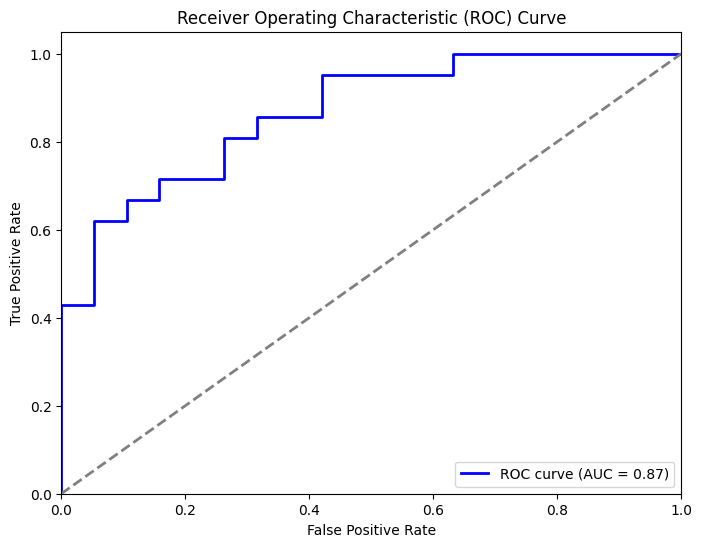

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate false positive rate, true positive rate, and thresholds
fpr, tpr, thresholds = roc_curve(y_test, predictions)

# Calculate the AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2)  # Diagonal line (random classifier)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

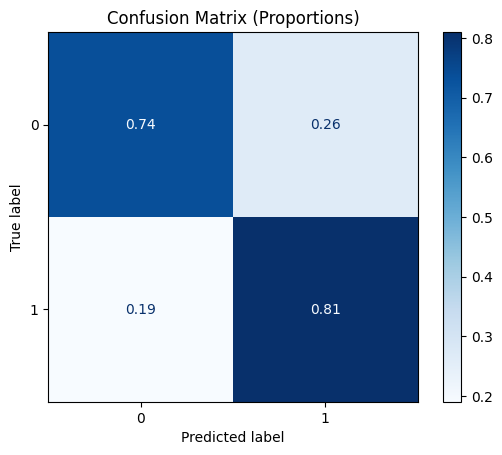

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
model.eval() # Set model to evaluation mode
with torch.no_grad():
    predictions = model(X_test).squeeze()
    y_pred = (predictions >= 0.5).float()

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Normalize the confusion matrix to show proportions
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


# Display confusion matrix
# Define a dummy clf object as it is used in ConfusionMatrixDisplay
class DummyClassifier:
    def __init__(self, classes):
        self.classes_ = classes

clf = DummyClassifier(classes=[0, 1])


disp = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=clf.classes_)
disp.plot(cmap=plt.cm.Blues, values_format=".2f") # Use ".2f" to format as floats with 2 decimal places
plt.title("Confusion Matrix (Proportions)")
plt.show()

Saving qbeta_5nt_fragment_geometry_binary_only.csv to qbeta_5nt_fragment_geometry_binary_only (1).csv
Uploaded file: qbeta_5nt_fragment_geometry_binary_only (1).csv
Dataset shape: (1411, 6)
Columns: ['angle_P1_P2_P3_deg', 'angle_P2_P3_P4_deg', 'angle_P3_P4_P5_deg', 'dihedral_P1_P2_P3_P4_deg', 'dihedral_P2_P3_P4_P5_deg', 'last_column_5P_status']
   angle_P1_P2_P3_deg  angle_P2_P3_P4_deg  angle_P3_P4_P5_deg  \
0          148.646968          154.117948          145.802022   
1          154.117948          145.802022          150.873055   
2          145.802022          150.873055          147.245119   
3          150.873055          147.245119          150.332498   
4          147.245119          150.332498          150.758303   

   dihedral_P1_P2_P3_P4_deg  dihedral_P2_P3_P4_P5_deg  last_column_5P_status  
0                 20.436360                 14.304255                      0  
1                 14.304255                 18.093356                      0  
2                 18.0933

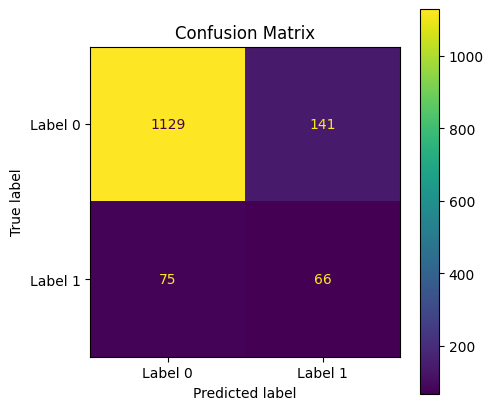

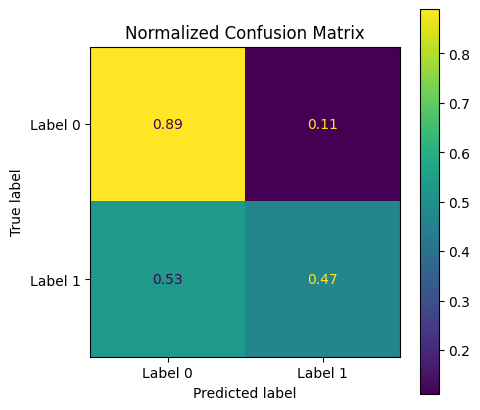

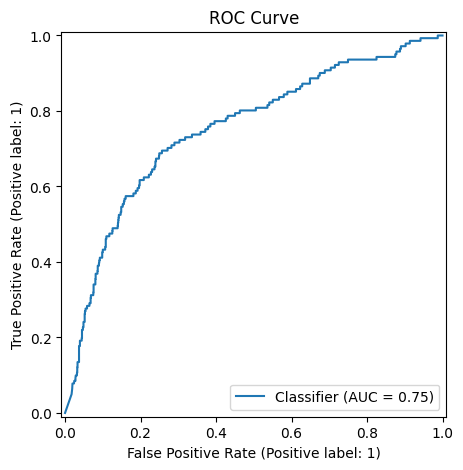

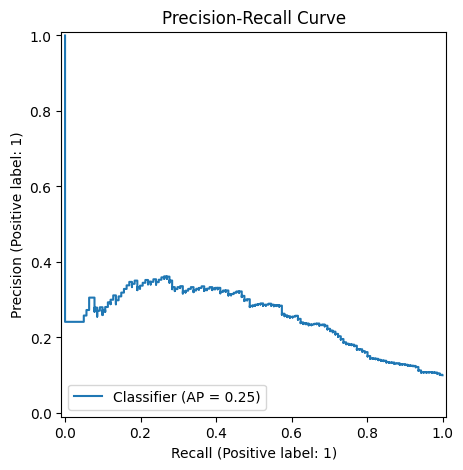

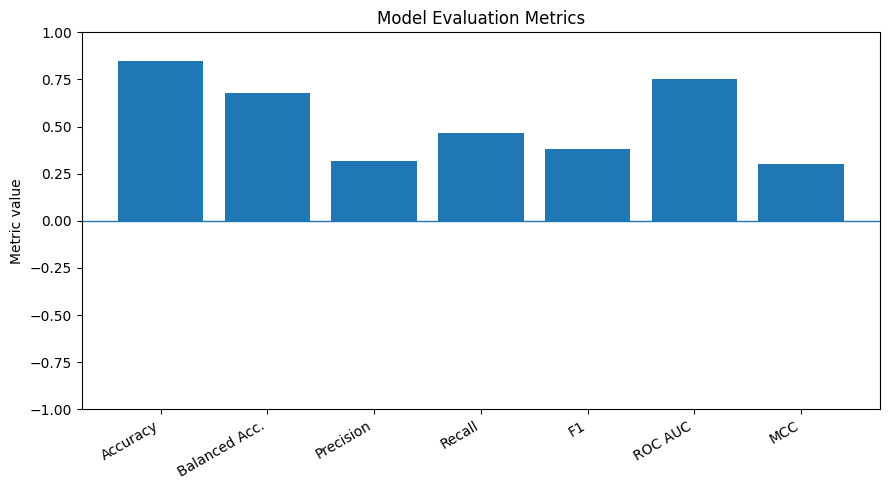


Prediction file saved as: qbeta_model_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==========================================
# Upload new dataset, evaluate trained model,
# and plot evaluation metrics in Colab
# ==========================================

from google.colab import files
import io
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# -------------------------------
# 1. Upload CSV file
# -------------------------------

uploaded = files.upload()
uploaded_filename = list(uploaded.keys())[0]

print("Uploaded file:", uploaded_filename)

df_test = pd.read_csv(io.BytesIO(uploaded[uploaded_filename]))

print("Dataset shape:", df_test.shape)
print("Columns:", df_test.columns.tolist())
print(df_test.head())

# -------------------------------
# 2. First five columns = input
#    Last column = label
# -------------------------------

X_new = df_test.iloc[:, :5].values.astype(np.float32)
y_true = df_test.iloc[:, -1].values

# Convert labels if needed
unique_labels = set(np.unique(y_true))

if unique_labels == {-1, 1}:
    y_true = ((y_true + 1) // 2).astype(int)
else:
    y_true = y_true.astype(int)

X_new_tensor = torch.tensor(X_new, dtype=torch.float32)

# -------------------------------
# 3. Predict with trained model
# -------------------------------

model.eval()

with torch.no_grad():
    outputs = model(X_new_tensor).squeeze()

    # If model output is logits, apply sigmoid.
    # If model already ends with Sigmoid, keep output directly.
    if outputs.min().item() < 0 or outputs.max().item() > 1:
        y_prob = torch.sigmoid(outputs).cpu().numpy()
    else:
        y_prob = outputs.cpu().numpy()

y_pred = (y_prob >= 0.5).astype(int)

# -------------------------------
# 4. Calculate metrics
# -------------------------------

accuracy = accuracy_score(y_true, y_pred)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
mcc = matthews_corrcoef(y_true, y_pred)

try:
    roc_auc = roc_auc_score(y_true, y_prob)
except ValueError:
    roc_auc = np.nan

cm = confusion_matrix(y_true, y_pred)

print("\n==============================")
print("Evaluation Metrics")
print("==============================")
print(f"Number of samples:  {len(y_true)}")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Balanced accuracy:  {balanced_acc:.4f}")
print(f"Precision:          {precision:.4f}")
print(f"Recall:             {recall:.4f}")
print(f"F1 score:           {f1:.4f}")
print(f"ROC AUC:            {roc_auc:.4f}")
print(f"MCC:                {mcc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, digits=4, zero_division=0))

# -------------------------------
# 5. Plot raw confusion matrix
# -------------------------------

fig, ax = plt.subplots(figsize=(5, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Label 0", "Label 1"])
disp.plot(ax=ax, values_format="d")
ax.set_title("Confusion Matrix")
plt.show()

# -------------------------------
# 6. Plot normalized confusion matrix
# -------------------------------

cm_norm = confusion_matrix(y_true, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(5, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=["Label 0", "Label 1"])
disp.plot(ax=ax, values_format=".2f")
ax.set_title("Normalized Confusion Matrix")
plt.show()

# -------------------------------
# 7. Plot ROC curve
# -------------------------------

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_true, y_prob, ax=ax)
ax.set_title("ROC Curve")
plt.show()

# -------------------------------
# 8. Plot Precision-Recall curve
# -------------------------------

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_true, y_prob, ax=ax)
ax.set_title("Precision-Recall Curve")
plt.show()

# -------------------------------
# 9. Plot metric summary bar chart
# -------------------------------

metric_names = [
    "Accuracy",
    "Balanced Acc.",
    "Precision",
    "Recall",
    "F1",
    "ROC AUC",
    "MCC"
]

metric_values = [
    accuracy,
    balanced_acc,
    precision,
    recall,
    f1,
    roc_auc,
    mcc
]

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(metric_names, metric_values)
ax.set_ylim(-1, 1)
ax.set_ylabel("Metric value")
ax.set_title("Model Evaluation Metrics")
ax.axhline(0, linewidth=1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# -------------------------------
# 10. Save predictions
# -------------------------------

df_output = df_test.copy()
df_output["true_label"] = y_true
df_output["predicted_probability"] = y_prob
df_output["predicted_label"] = y_pred

output_file = "qbeta_model_predictions.csv"
df_output.to_csv(output_file, index=False)

print(f"\nPrediction file saved as: {output_file}")
files.download(output_file)

Best Thresholds

Best threshold by label-1 F1:
threshold               0.510000
accuracy                0.848335
balanced_accuracy       0.679318
precision               0.321951
recall                  0.468085
specificity             0.890551
f1                      0.381503
mcc                     0.305221
TN                   1131.000000
FP                    139.000000
FN                     75.000000
TP                     66.000000
Name: 50, dtype: float64

Best threshold by balanced accuracy:
threshold              0.040000
accuracy               0.741318
balanced_accuracy      0.717594
precision              0.232057
recall                 0.687943
specificity            0.747244
f1                     0.347048
mcc                    0.285841
TN                   949.000000
FP                   321.000000
FN                    44.000000
TP                    97.000000
Name: 3, dtype: float64

Best threshold by MCC:
threshold               0.140000
accuracy                0.812

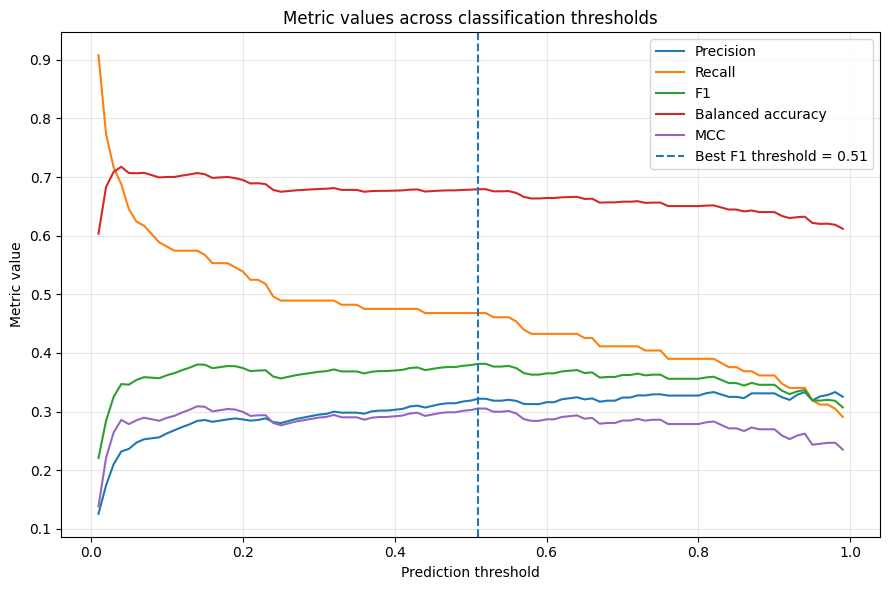

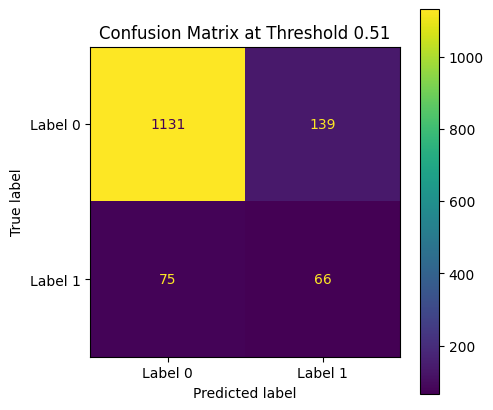

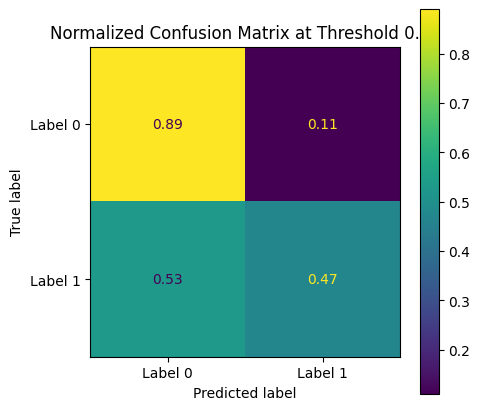


Saved: threshold_optimization_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==========================================
# Threshold optimization for imbalanced binary classification
# Uses y_true and y_prob from previous cell
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# -------------------------------
# 1. Scan thresholds
# -------------------------------

thresholds = np.arange(0.01, 1.00, 0.01)

rows = []

for th in thresholds:
    y_pred_th = (y_prob >= th).astype(int)

    acc = accuracy_score(y_true, y_pred_th)
    bal_acc = balanced_accuracy_score(y_true, y_pred_th)
    precision = precision_score(y_true, y_pred_th, zero_division=0)
    recall = recall_score(y_true, y_pred_th, zero_division=0)
    f1 = f1_score(y_true, y_pred_th, zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred_th)

    cm = confusion_matrix(y_true, y_pred_th)
    tn, fp, fn, tp = cm.ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    rows.append({
        "threshold": th,
        "accuracy": acc,
        "balanced_accuracy": bal_acc,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "mcc": mcc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_df = pd.DataFrame(rows)

# -------------------------------
# 2. Find best thresholds
# -------------------------------

best_f1_row = threshold_df.loc[threshold_df["f1"].idxmax()]
best_balacc_row = threshold_df.loc[threshold_df["balanced_accuracy"].idxmax()]
best_mcc_row = threshold_df.loc[threshold_df["mcc"].idxmax()]

print("==============================")
print("Best Thresholds")
print("==============================")
print("\nBest threshold by label-1 F1:")
print(best_f1_row)

print("\nBest threshold by balanced accuracy:")
print(best_balacc_row)

print("\nBest threshold by MCC:")
print(best_mcc_row)

# Choose one main threshold
# Usually for imbalanced biological positive detection, F1 or MCC is more useful than accuracy.
best_threshold = best_f1_row["threshold"]

print("\n==============================")
print(f"Using best F1 threshold: {best_threshold:.2f}")
print("==============================")

# -------------------------------
# 3. Evaluate at best threshold
# -------------------------------

y_pred_best = (y_prob >= best_threshold).astype(int)

print("\nClassification report at best threshold:")
print(classification_report(y_true, y_pred_best, digits=4, zero_division=0))

cm_best = confusion_matrix(y_true, y_pred_best)

print("Confusion matrix at best threshold:")
print(cm_best)

# -------------------------------
# 4. Plot metrics across thresholds
# -------------------------------

plt.figure(figsize=(9, 6))

plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")
plt.plot(threshold_df["threshold"], threshold_df["balanced_accuracy"], label="Balanced accuracy")
plt.plot(threshold_df["threshold"], threshold_df["mcc"], label="MCC")

plt.axvline(best_threshold, linestyle="--", label=f"Best F1 threshold = {best_threshold:.2f}")

plt.xlabel("Prediction threshold")
plt.ylabel("Metric value")
plt.title("Metric values across classification thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------------------
# 5. Plot confusion matrix at best threshold
# -------------------------------

fig, ax = plt.subplots(figsize=(5, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=["Label 0", "Label 1"]
)
disp.plot(ax=ax, values_format="d")
ax.set_title(f"Confusion Matrix at Threshold {best_threshold:.2f}")
plt.show()

# -------------------------------
# 6. Plot normalized confusion matrix
# -------------------------------

cm_best_norm = confusion_matrix(y_true, y_pred_best, normalize="true")

fig, ax = plt.subplots(figsize=(5, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_norm,
    display_labels=["Label 0", "Label 1"]
)
disp.plot(ax=ax, values_format=".2f")
ax.set_title(f"Normalized Confusion Matrix at Threshold {best_threshold:.2f}")
plt.show()

# -------------------------------
# 7. Save threshold scan results
# -------------------------------

threshold_df.to_csv("threshold_optimization_results.csv", index=False)
print("\nSaved: threshold_optimization_results.csv")

from google.colab import files
files.download("threshold_optimization_results.csv")